In [ ]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.motivating_example import MotivatingExample
import numpy as np
from src.data_generator import DataGenerator
from src.metrics import energy_distance

# Gaussian Mixture and Logistic $d=20$

In [3]:
from src.data_generator import DataGenerator
from typing import Optional
import torch
from src.mdm import ampute_mar
from scipy.stats import gaussian_kde
from torch.distributions import Normal, MultivariateNormal
from joblib import Parallel, delayed


class AmputeMAR(DataGenerator):
    def __init__(
        self,
        pc_range: np.ndarray = np.arange(1.0, 0.0, -0.1),
        k_range: tuple = (0,20),
        B: int = 20,
        n_jobs: int = 15,
        distr: str = "Normal",
        mu: Optional[torch.Tensor] = None,
        sigma: Optional[torch.Tensor] = None,
        pi: Optional[torch.Tensor] = None,
        alpha: float = 0.7,
        c: float = 0.01,
        df: Optional[int] = None,
        device: str = "cpu",
        dtype: torch.dtype = torch.float64,
    ):
        super().__init__(
            distr=distr,
            mu=mu,
            sigma=sigma,
            pi=pi,
            alpha=alpha,
            c=c,
            df=df,
            device=device,
            dtype=dtype,
        )
        self.pc_range = pc_range
        self.k_range = k_range
        self.B = B
        self.n_jobs = n_jobs

    def _missingness_dist(self, d, prob_complete_case):
        """
        Compute the marginal of missingness pattern M
        - input1: the probability of the completely observed
        - input2: the probability of the worst missingness, i.e., all missing except the last column
        Return: pmf of M
        """
        n = 2**(d-1)
        probs = np.empty(n)
        probs[-1] = prob_complete_case
        mu = (1-prob_complete_case)/(n-1)
        probs[:-1] = np.abs(np.random.normal(loc=mu, size=n-1))
        probs[:-1] /= probs[:-1].sum()
        probs[:-1] *= 1 - prob_complete_case
        return probs

    def _gaussian_mixture_fit(self, X, d, prob_complete_case):
        if prob_complete_case == 1.0:
            M = torch.ones_like(X, device=X.device)
        else:
            probs = self._missingness_dist(d, prob_complete_case)
            _, M = ampute_mar(X, probs)

        model = GaussianMixtureMAR(k_range=self.k_range)
        model.fit(X, M)
        return model

    def _gaussian_mixture_density_score(self, X, pi, mu, sigma):
        if sigma.shape == mu.shape:
            log_prob = Normal(mu, sigma).log_prob(X[:, None, :]).sum(dim=2) # (n,k,d) -> (n,k)
        else:
            log_prob = MultivariateNormal(mu, sigma).log_prob(X[:,None,:])

        log_prob += pi.log()
        
        return log_prob.logsumexp(dim=1).mean()

    def _evaluate(self, n, d):
        X = self.sample_truth(n, d)
        Xtest = self.sample_truth(n, d)
        self.dscore0 = self._gaussian_mixture_density_score(X, mu=self.mu, sigma=self.sigma, pi=self.pi)

        empirical_kl = np.empty(len(self.pc_range) + 1)
        energy_distances = np.empty(len(self.pc_range) + 1)
        
        kde = gaussian_kde(X.T)
        empirical_kl[0] = np.mean(kde.logpdf(X.T)) - self.dscore0
        energy_distances[0] = energy_distance(Xtest, torch.tensor(kde.resample(n)).T).item()

        for i in range(len(self.pc_range)):
            model = self._gaussian_mixture_fit(X, d, self.pc_range[i])
            pi, mu, sigma = model.best_params
            empirical_kl[i+1] = self._gaussian_mixture_density_score(X, pi, mu, sigma) - self.dscore0
            energy_distances[i+1] = energy_distance(Xtest, model.sample(n)[0]).item()
        
        return empirical_kl, energy_distances

    def evaluate(self, n, d):
        self.results = np.array(
            Parallel(self.n_jobs)(
                delayed(self._evaluate)(n, d)
                for _ in range(self.B)
            )
        )
        return self
        

    def plot_results(self):
        pass

Error importing in API mode: ImportError("dlopen(/Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Trying to import in ABI mode.


In [4]:
n = 2000
d = 20
k = 10
mu0 = torch.rand((k, d)) * 2 - 1 # [-1, 1]
A = torch.randn(k, d, d)
sigma0 = A @ A.transpose(-1, -2) + 1e-4 * torch.eye(d)
pi0 = torch.rand(k) + 0.1
pi0 = pi0 / pi0.sum()

In [5]:
amputed = AmputeMAR(distr='gaussian_mixture', mu=mu0, sigma=sigma0, pi=pi0)
amputed.evaluate(n, d)

Error importing in API mode: ImportError("dlopen(/Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not loaded: /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib\n  Referenced from: <1984CB9B-890E-3855-A246-270AC6AC4C62> /Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so\n  Reason: tried: '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file), '/Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/lib/libRblas.dylib' (no such file)")
Error importing in API mode: ImportError("dlopen(/Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/_rinterface_cffi_api.abi3.so, 0x0002): Library not

In [9]:
results = amputed.results

In [10]:
from src.utils import plot1

TypeError: join() argument must be str, bytes, or os.PathLike object, not 'NoneType'

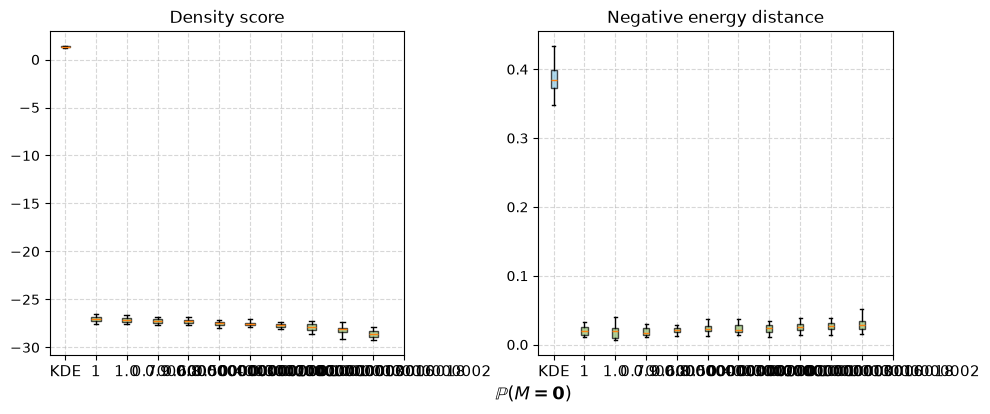

R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-console: 
  
R callback write-console: There were 50 or more warnings (use warnings() to see the first 50)  
R callback write-conso

In [11]:
plot1(results[:,0,:], results[:,1,:], np.arange(1,0,-0.1))